# Deep Learning para visión de computadoras
## Lab 3.3 GAN condicional, FID y aumento con datos sintéticos

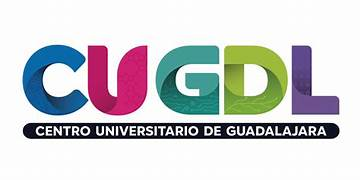

# Explica que es la aumentacion de datos coloca una imagen que lo ejemplifique y menciona cuales son las ventajas de aplicarlo en tu proyecto

[Aumento de datos con Ultralytics YOLO](https://docs.ultralytics.com/es/guides/yolo-data-augmentation)

La aumentación de datos consiste en generar nuevas muestras de entrenamiento a partir de las imágenes reales que ya tenemos, aplicando transformaciones controladas que no cambian la etiqueta original. Sirve para ampliar la variedad del conjunto de entrenamiento cuando recolectar y etiquetar más fotos no es viable.

En la práctica suele dividirse en dos enfoques. El aumento clásico aplica operaciones directas sobre los píxeles, como desplazar la imagen unos cuantos píxeles, rotarla ligeramente, cambiar su escala o ajustar brillo y contraste. El aumento sintético, en cambio, entrena un modelo generativo (como una cGAN) para producir ejemplos nuevos de cada clase desde cero. En la celda de abajo se genera un ejemplo visual con un dígito manuscrito real y varias transformaciones básicas.

Para mi proyecto integrador de síntesis dinámica de caligrafía manuscrita mediante cGAN, usar aumentación ayuda en tres puntos concretos:

- Mi conjunto inicial es pequeño (alrededor de 300 caracteres escritos a mano y segmentados), así que aumentar los datos evita que el clasificador y el discriminador memoricen siempre los mismos trazos.
- Al aplicar aumento diferenciable durante el entrenamiento adversarial, el discriminador deja de saturarse tan rápido y sigue enviando gradientes útiles al generador.
- Pequeñas traslaciones (±2 px) y rotaciones suaves (±12°) imitan la variación natural al escribir a mano. Aquí es necesario elegir bien las transformaciones: a diferencia de prendas de ropa u objetos simétricos, en texto no se puede usar espejo horizontal porque cambia o invalida letras y dígitos como 2, 3, 5 o /d.

¿cGAN o aumento clásico? Datos sintéticos con pocos datos reales?
Si solo tengo 50 imágenes etiquetadas por clase, ¿vale la pena entrenar una GAN condicional para generar más datos, o basta con el aumento de datos clásico (volteos, rotaciones, traslaciones)?

Con las 60 000 imágenes de FashionMNIST cualquier CNN supera el 90 % y no se nota ninguna diferencia. Con 500 imágenes (50 por clase) el problema se vuelve real y medible.

Las tres reglas de un experimento honesto
Sin fuga: la cGAN solo ve las mismas 500 imágenes que el clasificador.
Mismo presupuesto: todos los clasificadores tienen la misma arquitectura y el mismo número de pasos de entrenamiento (no de épocas: con más imágenes habría más pasos y la comparación sería injusta).
Evaluación en reales y con varias semillas: siempre en las 10 000 imágenes reales de prueba, con 3 semillas, reportando media ± desviación.

## Librerías

In [1]:
import os, time, math, copy, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision
from torchvision import datasets
from torchvision.utils import make_grid
from scipy import linalg
from IPython.display import display
warnings.filterwarnings("ignore")

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch", torch.__version__, "| dispositivo:", DEVICE,
      "(" + torch.cuda.get_device_name(0) + ")" if DEVICE.type == "cuda" else "← activa la GPU: Entorno de ejecución → Cambiar tipo de entorno → T4")

def fijar_semilla(s=0):
    torch.manual_seed(s); np.random.seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)

def mostrar_grid(x, titulo="", nrow=10, tam=(8, 8)):
    """x en [-1, 1], forma (N, C, H, W)."""
    g = make_grid(x.detach().cpu()[: nrow * nrow], nrow=nrow, normalize=True, value_range=(-1, 1), pad_value=1)
    plt.figure(figsize=tam); plt.imshow(g.permute(1, 2, 0).numpy(), cmap="gray"); plt.axis("off"); plt.title(titulo); plt.show()

PyTorch 2.14.1+cu130 | dispositivo: cuda (Tesla T4)


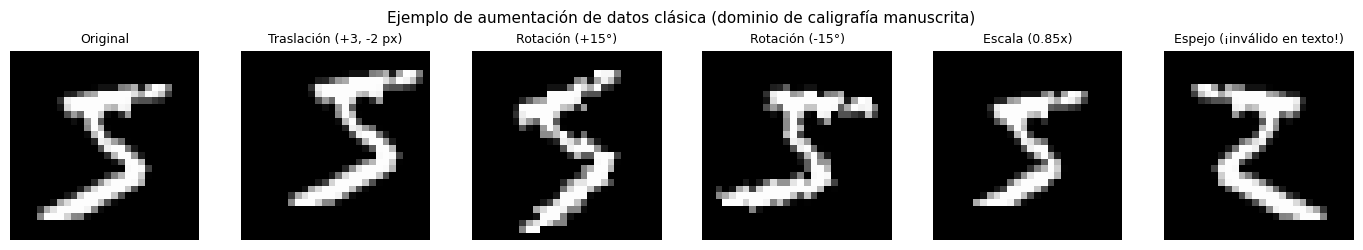

In [2]:
# Ejemplo visual de aumentación de datos clásica sobre una muestra real
import torchvision.transforms.functional as TF
_ds_ej = datasets.MNIST("datos", train=True, download=True)
_img_ej = _ds_ej[0][0]  # dígito manuscrito real ('5')
_imgs_aum = [
    ("Original", _img_ej),
    ("Traslación (+3, -2 px)", TF.affine(_img_ej, angle=0, translate=(3, -2), scale=1.0, shear=0)),
    ("Rotación (+15°)", TF.rotate(_img_ej, 15)),
    ("Rotación (-15°)", TF.rotate(_img_ej, -15)),
    ("Escala (0.85x)", TF.affine(_img_ej, angle=0, translate=(0, 0), scale=0.85, shear=0)),
    ("Espejo (¡inválido en texto!)", TF.hflip(_img_ej)),
]
fig, axes = plt.subplots(1, len(_imgs_aum), figsize=(14, 2.5))
for ax, (tit, im) in zip(axes, _imgs_aum):
    ax.imshow(im, cmap="gray"); ax.set_title(tit, fontsize=9); ax.axis("off")
plt.suptitle("Ejemplo de aumentación de datos clásica (dominio de caligrafía manuscrita)", fontsize=11)
plt.tight_layout(); plt.show()

In [3]:
NOMBRES_CLASES = {
    "FashionMNIST": ["camiseta", "pantalón", "suéter", "vestido", "abrigo", "sandalia", "camisa", "tenis", "bolsa", "botín"],
    "MNIST": [str(i) for i in range(10)],
    "CIFAR10": ["avión", "auto", "pájaro", "gato", "venado", "perro", "rana", "caballo", "barco", "camión"],
}

def cargar_tensor(nombre="FashionMNIST", split="train"):
    """Descarga el dataset y lo deja COMPLETO en memoria como tensor (N, C, 32, 32) en [-1, 1].
    Tenerlo en la GPU evita el DataLoader y acelera muchísimo el entrenamiento de GANs pequeñas."""
    clase = getattr(datasets, nombre)
    ds = clase("datos", train=(split == "train"), download=True)
    x = torch.as_tensor(np.asarray(ds.data))
    y = torch.as_tensor(np.asarray(ds.targets)).long()
    if x.ndim == 3:                          # escala de grises 28x28 → (N, 1, 32, 32) con relleno de 2 px
        x = F.pad(x.unsqueeze(1), (2, 2, 2, 2))
    else:                                    # CIFAR10 viene como (N, 32, 32, 3)
        x = x.permute(0, 3, 1, 2)
    x = x.float().div(255).mul(2).sub(1)    # [0, 255] → [-1, 1] (coincide con la tanh del generador)
    return x.to(DEVICE), y.to(DEVICE)

def lotes(x, y, batch, mezclar=True):
    idx = torch.randperm(len(x), device=x.device) if mezclar else torch.arange(len(x), device=x.device)
    for i in range(0, len(x) - batch + 1, batch):   # se descarta el último lote incompleto (BN lo agradece)
        j = idx[i:i + batch]
        yield x[j], y[j]

In [4]:
def _bn(n, usar):            # BatchNorm o "nada", para poder hacer ablaciones
    return nn.BatchNorm2d(n) if usar else nn.Identity()

class Generador(nn.Module):
    """DCGAN para 32x32: z (nz) → 4x4 → 8x8 → 16x16 → 32x32. Sin capas densas, solo convoluciones transpuestas."""
    def __init__(self, nz=100, ngf=64, canales=1, bn=True):
        super().__init__()
        b = not bn            # si hay BN el sesgo es redundante
        self.red = nn.Sequential(
            nn.ConvTranspose2d(nz, ngf * 4, 4, 1, 0, bias=b), _bn(ngf * 4, bn), nn.ReLU(True),       # 4x4
            nn.ConvTranspose2d(ngf * 4, ngf * 2, 4, 2, 1, bias=b), _bn(ngf * 2, bn), nn.ReLU(True),  # 8x8
            nn.ConvTranspose2d(ngf * 2, ngf, 4, 2, 1, bias=b), _bn(ngf, bn), nn.ReLU(True),          # 16x16
            nn.ConvTranspose2d(ngf, canales, 4, 2, 1, bias=True), nn.Tanh(),                        # 32x32 en [-1, 1]
        )
    def forward(self, z):
        return self.red(z.view(z.size(0), -1, 1, 1))

class Discriminador(nn.Module):
    """Espejo del generador: convoluciones con stride 2 en lugar de pooling, LeakyReLU, y un LOGIT final.
    No ponemos Sigmoid: usamos BCEWithLogitsLoss, que es numéricamente estable."""
    def __init__(self, ndf=64, canales=1, bn=True):
        super().__init__()
        b = not bn
        self.red = nn.Sequential(
            nn.Conv2d(canales, ndf, 4, 2, 1, bias=True), nn.LeakyReLU(0.2, True),                  # 16x16 (sin BN en la 1a capa)
            nn.Conv2d(ndf, ndf * 2, 4, 2, 1, bias=b), _bn(ndf * 2, bn), nn.LeakyReLU(0.2, True),    # 8x8
            nn.Conv2d(ndf * 2, ndf * 4, 4, 2, 1, bias=b), _bn(ndf * 4, bn), nn.LeakyReLU(0.2, True),# 4x4
            nn.Conv2d(ndf * 4, 1, 4, 1, 0, bias=True),                                             # 1x1 → logit
        )
    def forward(self, x):
        return self.red(x).view(-1)

def init_dcgan(m):
    """Inicialización del artículo DCGAN (Radford et al., 2016): pesos ~ N(0, 0.02); BN: γ ~ N(1, 0.02), β = 0."""
    if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d, nn.Linear)):
        nn.init.normal_(m.weight, 0.0, 0.02)
        if m.bias is not None: nn.init.zeros_(m.bias)
    elif isinstance(m, nn.BatchNorm2d):
        nn.init.normal_(m.weight, 1.0, 0.02); nn.init.zeros_(m.bias)

def contar_parametros(m):
    return sum(p.numel() for p in m.parameters())

In [5]:
class GeneradorCond(nn.Module):
    """cGAN (Mirza y Osindero, 2014) con arquitectura DCGAN.
    La etiqueta y entra como un embedding aprendido que se CONCATENA al ruido z."""
    def __init__(self, nz=100, n_clases=10, dim_emb=50, ngf=64, canales=1):
        super().__init__()
        self.emb = nn.Embedding(n_clases, dim_emb)
        self.g = Generador(nz + dim_emb, ngf, canales, bn=True)
    def forward(self, z, y):
        return self.g(torch.cat([z, self.emb(y)], dim=1))

class DiscriminadorCond(nn.Module):
    """La etiqueta se convierte en un 'mapa' de 32x32 y se añade como canal extra a la imagen:
    D '¿es una imagen real DE ESTA CLASE?'."""
    def __init__(self, n_clases=10, ndf=64, canales=1, lado=32):
        super().__init__()
        self.lado = lado
        self.emb = nn.Embedding(n_clases, lado * lado)
        self.d = Discriminador(ndf, canales + 1, bn=True)
    def forward(self, x, y):
        mapa = self.emb(y).view(-1, 1, self.lado, self.lado)
        return self.d(torch.cat([x, mapa], dim=1))

In [6]:
class Juez(nn.Module):
    """CNN pequeña entrenada con datos REALES. Nos sirve de 'evaluador externo' de las imágenes generadas:
    (1) qué clase cree que es cada muestra → cobertura de modos; (2) sus características de 128-d → FID de dominio."""
    def __init__(self, canales=1, n_clases=10):
        super().__init__()
        self.cuerpo = nn.Sequential(
            nn.Conv2d(canales, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),   # 16
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),        # 8
            nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(), nn.AdaptiveAvgPool2d(1),
            nn.Flatten())
        self.cabeza = nn.Linear(128, n_clases)
    def forward(self, x): return self.cabeza(self.cuerpo(x))
    @torch.no_grad()
    def caracteristicas(self, x, lote=500):
        self.eval(); return torch.cat([self.cuerpo(x[i:i + lote]) for i in range(0, len(x), lote)])
    @torch.no_grad()
    def probabilidades(self, x, lote=500):
        self.eval(); return torch.cat([F.softmax(self(x[i:i + lote]), 1) for i in range(0, len(x), lote)])

def entrenar_juez(x, y, x_te, y_te, epocas=3, batch=256, aumento=False, semilla=0, verbose=True):
    fijar_semilla(semilla)
    m = Juez(x.shape[1], int(y.max()) + 1).to(DEVICE)
    opt = torch.optim.Adam(m.parameters(), 1e-3)
    for ep in range(epocas):
        m.train()
        for xb, yb in lotes(x, y, min(batch, len(x))):
            if aumento:   # aumento "clásico": desplazamientos aleatorios de ±2 px y espejo horizontal
                xb = torch.roll(xb, shifts=(int(np.random.randint(-2, 3)), int(np.random.randint(-2, 3))), dims=(2, 3))
                if np.random.rand() < 0.5: xb = xb.flip(3)
            loss = F.cross_entropy(m(xb), yb)
            opt.zero_grad(); loss.backward(); opt.step()
    acc = (m.probabilidades(x_te).argmax(1) == y_te).float().mean().item()
    if verbose: print(f"Juez: exactitud en prueba real = {acc:.3f}")
    return m, acc

In [7]:
def estadisticos(feats):
    f = feats.double().cpu().numpy()
    return f.mean(0), np.cov(f, rowvar=False)

def distancia_frechet(mu1, s1, mu2, s2):
    """FID = ||μ1 − μ2||² + Tr(Σ1 + Σ2 − 2 (Σ1 Σ2)^{1/2})   (Heusel et al., 2017)"""
    diff = mu1 - mu2
    covmean = linalg.sqrtm(s1 @ s2)
    if not np.isfinite(covmean).all():          # estabilización numérica recomendada en la implementación oficial
        eps = np.eye(len(s1)) * 1e-6
        covmean = linalg.sqrtm((s1 + eps) @ (s2 + eps))
    covmean = np.real(covmean)
    return float(diff @ diff + np.trace(s1) + np.trace(s2) - 2 * np.trace(covmean))

def fid_dominio(juez, x_a, x_b):
    """FID calculado con las características del JUEZ (128-d)"""
    return distancia_frechet(*estadisticos(juez.caracteristicas(x_a)), *estadisticos(juez.caracteristicas(x_b)))

In [8]:
DATASET = "FashionMNIST"
X_tr, Y_tr = cargar_tensor(DATASET, "train"); X_te, Y_te = cargar_tensor(DATASET, "test")
CLASES = NOMBRES_CLASES[DATASET]; CANALES = X_tr.shape[1]; N_CLASES = len(CLASES)

RUTA_JUEZ = f"juez_{DATASET}.pt"     # sube el del jueves 29 con: from google.colab import files; files.upload()
if os.path.exists(RUTA_JUEZ):
    juez = Juez(CANALES).to(DEVICE); juez.load_state_dict(torch.load(RUTA_JUEZ, map_location=DEVICE)); juez.eval()
    print("Juez cargado · exactitud en prueba:", round((juez.probabilidades(X_te).argmax(1) == Y_te).float().mean().item(), 3))
else:
    juez, _ = entrenar_juez(X_tr, Y_tr, X_te, Y_te, epocas=3); torch.save(juez.state_dict(), RUTA_JUEZ)

Juez cargado · exactitud en prueba: 0.77


## Parte

DCGAN (pérdida no saturante, BCE con logits, *label smoothing*, inicialización N(0, 0.02), Adam 2·10⁻⁴ y β₁ = 0.5). Cambia lo que entra a cada red:

* **G(z, y)**: el *embedding* de la etiqueta se concatena al ruido.
* **D(x, y)**: la etiqueta entra como canal extra. Para los lotes falsos usamos **etiquetas aleatorias** uniformes, de modo que G practica todas las clases por igual.

Añadimos dos opciones útiles cuando hay **pocos datos**: ruido de instancia y un **aumento diferenciable** (desplazamiento y espejo aplicados **por igual** a reales y falsas antes de D, en el espíritu de *DiffAugment*, Zhao et al., 2020) para que D no memorice el conjunto pequeño.

El entrenamiento se mide en **iteraciones** (no épocas) para poder comparar un dataset de 60 000 imágenes con uno de 500.

In [9]:
def aumento_diferenciable(x, activo):
    if not activo: return x
    dx, dy = np.random.randint(-3, 4, size=2)
    x = torch.roll(x, shifts=(int(dx), int(dy)), dims=(2, 3))
    return x.flip(3) if np.random.rand() < 0.5 else x

@torch.no_grad()
def muestras_cond(G, n_por_clase=100, nz=100, semilla=0):
    g = torch.Generator(device=DEVICE).manual_seed(semilla)
    y = torch.arange(N_CLASES, device=DEVICE).repeat_interleave(n_por_clase)
    z = torch.randn(len(y), nz, device=DEVICE, generator=g)
    G.eval(); x = torch.cat([G(z[i:i + 500], y[i:i + 500]) for i in range(0, len(y), 500)]); G.train()
    return x, y

@torch.no_grad()
def evaluar_cgan(G, nz=100, n_por_clase=200):
    x, y = muestras_cond(G, n_por_clase, nz, semilla=123)
    pred = juez.probabilidades(x).argmax(1)
    return dict(acc_condicional=round((pred == y).float().mean().item(), 3),
                fid_dominio=round(fid_dominio(juez, X_te[:len(x)], x), 2))

def entrenar_cgan(x, y, iteraciones=4000, batch=128, nz=100, suavizado=0.9, ruido_instancia=0.0,
                  aumento_D=False, semilla=0, cada=500, nombre="cgan"):
    fijar_semilla(semilla)
    G = GeneradorCond(nz, N_CLASES, 50, 64, CANALES).to(DEVICE)
    D = DiscriminadorCond(N_CLASES, 64, CANALES).to(DEVICE)
    G.apply(init_dcgan); D.apply(init_dcgan)
    oG = torch.optim.Adam(G.parameters(), 2e-4, betas=(0.5, 0.999))
    oD = torch.optim.Adam(D.parameters(), 2e-4, betas=(0.5, 0.999))
    bce = nn.BCEWithLogitsLoss()
    batch = min(batch, len(x)); flujo = iter(()); hist, t0 = [], time.time()
    for it in range(1, iteraciones + 1):
        try: xr, yr = next(flujo)
        except StopIteration:
            flujo = lotes(x, y, batch); xr, yr = next(flujo)
        b = len(xr); sigma = ruido_instancia * (1 - it / iteraciones)
        rd = (lambda t: aumento_diferenciable(t + sigma * torch.randn_like(t), aumento_D)) if sigma > 0 else (lambda t: aumento_diferenciable(t, aumento_D))
        # (1) D: real de su clase → suavizado ; falsa con etiqueta aleatoria → 0
        yf = torch.randint(0, N_CLASES, (b,), device=DEVICE)
        with torch.no_grad(): xf = G(torch.randn(b, nz, device=DEVICE), yf)
        o_r, o_f = D(rd(xr), yr), D(rd(xf), yf)
        lD = bce(o_r, torch.full_like(o_r, suavizado)) + bce(o_f, torch.zeros_like(o_f))
        oD.zero_grad(); lD.backward(); oD.step()
        # (2) G: no saturante
        yg = torch.randint(0, N_CLASES, (b,), device=DEVICE)
        o_g = D(rd(G(torch.randn(b, nz, device=DEVICE), yg)), yg)
        lG = bce(o_g, torch.ones_like(o_g))
        oG.zero_grad(); lG.backward(); oG.step()
        if it % cada == 0 or it == iteraciones:
            ev = evaluar_cgan(G, nz)
            hist.append(dict(iteracion=it, loss_D=lD.item(), loss_G=lG.item(), D_x=torch.sigmoid(o_r).mean().item(),
                             D_Gz=torch.sigmoid(o_f).mean().item(), **ev))
            print(f"[{nombre}] it {it:>5}/{iteraciones}  loss_D {lD.item():.3f}  loss_G {lG.item():.3f}  "
                  f"acc_cond {ev['acc_condicional']:.3f}  FID-d {ev['fid_dominio']:.1f}  ({time.time() - t0:.0f} s)")
    return G, pd.DataFrame(hist)

ITER_COMPLETO = 4000      # ≈ 8.5 épocas de FashionMNIST con lotes de 128
G_completo, h_completo = entrenar_cgan(X_tr, Y_tr, ITER_COMPLETO, nombre="cGAN-60k")

[cGAN-60k] it   500/4000  loss_D 1.113  loss_G 1.573  acc_cond 0.342  FID-d 14.5  (28 s)
[cGAN-60k] it  1000/4000  loss_D 0.961  loss_G 2.447  acc_cond 0.614  FID-d 7.3  (58 s)
[cGAN-60k] it  1500/4000  loss_D 1.061  loss_G 2.223  acc_cond 0.651  FID-d 3.5  (87 s)
[cGAN-60k] it  2000/4000  loss_D 1.168  loss_G 1.140  acc_cond 0.668  FID-d 2.6  (116 s)
[cGAN-60k] it  2500/4000  loss_D 1.069  loss_G 1.338  acc_cond 0.644  FID-d 2.0  (145 s)
[cGAN-60k] it  3000/4000  loss_D 1.122  loss_G 1.580  acc_cond 0.687  FID-d 1.4  (174 s)
[cGAN-60k] it  3500/4000  loss_D 1.101  loss_G 1.494  acc_cond 0.690  FID-d 1.4  (203 s)
[cGAN-60k] it  4000/4000  loss_D 1.071  loss_G 1.416  acc_cond 0.745  FID-d 0.6  (232 s)


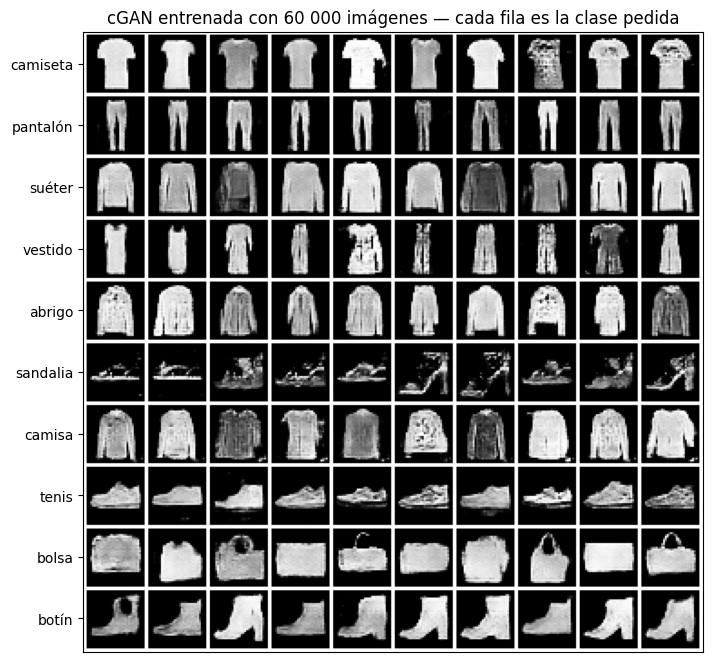

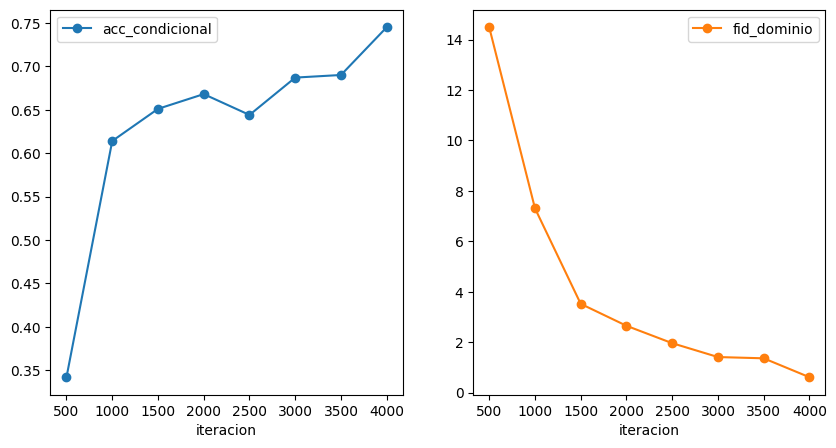

In [10]:
def rejilla_por_clase(G, titulo, nz=100):
    x, _ = muestras_cond(G, n_por_clase=10, nz=nz, semilla=7)
    g = make_grid(x.cpu(), nrow=10, normalize=True, value_range=(-1, 1), pad_value=1)
    plt.figure(figsize=(8, 8.4)); plt.imshow(g.permute(1, 2, 0)); plt.title(titulo)
    plt.yticks([17 + 34 * i for i in range(N_CLASES)], CLASES); plt.xticks([]); plt.show()

rejilla_por_clase(G_completo, "cGAN entrenada con 60 000 imágenes — cada fila es la clase pedida")
h_completo.plot(x="iteracion", y=["acc_condicional", "fid_dominio"], subplots=True, marker="o", figsize=(10, 5), layout=(1, 2)); plt.show()

Inspección visual ¿todas las filas corresponden a la clase pedida? ¿Hay diversidad de cada fila (colores, formas, poses) o se repite la misma prenda?

La mayoría de las filas sí corresponden a la clase pedida, sobre todo en prendas con silueta marcada como pantalón, sandalia, tenis, bolsa y botín. En cambio, en filas como camiseta, suéter y camisa varias muestras se ven borrosas o se confunden entre sí. Dentro de cada fila hay variedad razonable en tonos de gris, ancho de la prenda y forma (no se repite exactamente la misma imagen en toda la fila), aunque algunas clases se ven más limpias que otras. Al llegar a las 4000 iteraciones el modelo alcanzó una exactitud condicional de 0.745 y un FID de dominio de 0.6.

## Parte B

Dos preguntas distintas, dos métricas:
* **¿Genera lo que se le pide?** → *exactitud condicional*: el juez clasifica las muestras de la clase *c* y medimos cuántas reconoce como *c*.
* **¿Se parece a la distribución real de esa clase?** → **FID de dominio por clase**: 1000 generadas de la clase *c* vs. las 1000 reales de prueba de esa clase.

,clase,acc_condicional,fid_dominio
0,camiseta,0.421,1.196
1,pantalón,0.989,1.223
2,suéter,0.084,1.133
3,vestido,0.805,1.249
4,abrigo,0.979,0.714
5,sandalia,0.999,1.152
6,camisa,0.368,1.659
7,tenis,0.921,1.364
8,bolsa,0.904,2.314
9,botín,0.916,1.017


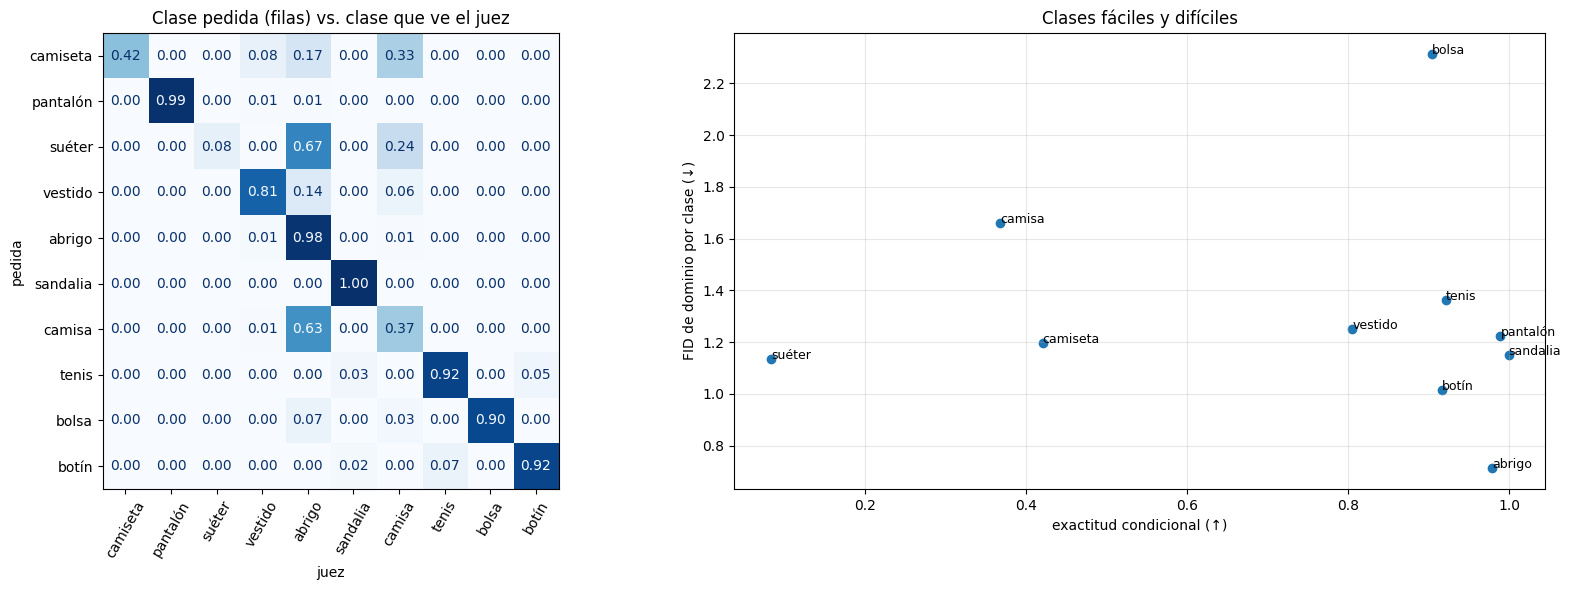

In [11]:
@torch.no_grad()
def evaluacion_por_clase(G, nz=100, n=1000):
    x, y = muestras_cond(G, n, nz, semilla=99)
    pred = juez.probabilidades(x).argmax(1)
    filas = []
    for c in range(N_CLASES):
        xc = x[y == c]; xr = X_te[Y_te == c][:n]
        filas.append(dict(clase=CLASES[c], acc_condicional=(pred[y == c] == c).float().mean().item(),
                          fid_dominio=fid_dominio(juez, xr, xc)))
    return pd.DataFrame(filas), y.cpu(), pred.cpu()

tabla_clase, y_ped, y_pred = evaluacion_por_clase(G_completo)
display(tabla_clase.round(3))

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
fig, ax = plt.subplots(1, 2, figsize=(17, 6))
ConfusionMatrixDisplay(confusion_matrix(y_ped, y_pred, normalize="true"), display_labels=CLASES).plot(
    ax=ax[0], cmap="Blues", values_format=".2f", colorbar=False)
ax[0].set(title="Clase pedida (filas) vs. clase que ve el juez", xlabel="juez", ylabel="pedida"); ax[0].tick_params(axis="x", rotation=60)
ax[1].scatter(tabla_clase.acc_condicional, tabla_clase.fid_dominio)
for _, f in tabla_clase.iterrows(): ax[1].annotate(f.clase, (f.acc_condicional, f.fid_dominio), fontsize=9)
ax[1].set(xlabel="exactitud condicional (↑)", ylabel="FID de dominio por clase (↓)", title="Clases fáciles y difíciles"); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.savefig("cgan_evaluacion_por_clase.png", dpi=110); plt.show()

¿Qué clases confunde más la cGAN? ¿Coinciden con las que confunde un clasificador normal (p. ej., camisa/camiseta/suéter/abrigo)? ¿Es un problema del generador, del juez, o de los datos?

Las clases con peor exactitud condicional fueron suéter (0.084), camisa (0.368) y camiseta (0.421). En el otro extremo quedaron sandalia (0.999), pantalón (0.989), abrigo (0.979), tenis (0.921) y botín (0.916), mientras que el FID de dominio más alto fue el de bolsa (2.314) pese a tener buena exactitud condicional (0.904).

Estas confusiones coinciden con las de cualquier clasificador normal en FashionMNIST, donde las prendas superiores comparten casi la misma silueta a 32×32 en escala de grises. El problema viene de los tres lados a la vez. Los datos tienen ambigüedad visual de origen, el generador suaviza detalles finos como cuellos o mangas y acerca suéter y camisa a otras prendas superiores, y el propio juez (que solo entrenó 3 épocas y llegó a 0.770 en prueba real) tampoco separa bien ese grupo de clases.

## Parte C

¿Ayudan los datos sintéticos cuando hay pocos reales?



**Escenario.** Solo tenemos `N_POR_CLASE` imágenes reales etiquetadas por clase. Comparamos:

| Clave | Datos de entrenamiento del clasificador | Protocolo |
|---|---|---|
| `R` | Solo las imágenes reales limitadas | TRTR (referencia) |
| `R+aum` | Reales limitadas + aumento clásico (desplazamiento ±2 px, espejo) | TRTR con aumento |
| `S_honesta` | Solo sintéticas de una cGAN entrenada **con las mismas imágenes limitadas** | TSTR |
| `R+S_honesta` | Reales limitadas + sintéticas honestas | TRSTR |
| `R+S_fuga` ⚠️ | Reales limitadas + sintéticas de la cGAN de la Parte A (vio **60 000** imágenes) | **No válido como resultado:** cota con fuga de información |
| `R_60k` | Las 60 000 reales | Techo de referencia |

Datos limitados: 500 imágenes reales (50 por clase)


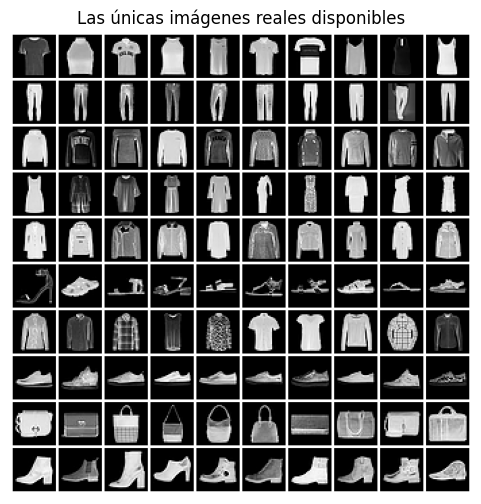

In [12]:
N_POR_CLASE = 50          # probar 20, 50 o 200
SINT_POR_CLASE = 500      # imágenes sintéticas por clase
PASOS_CLF = 800           # mismo presupuesto de entrenamiento para todos los clasificadores
SEMILLAS = [0, 1, 2]

def subconjunto_limitado(n, semilla=0):
    g = torch.Generator(device="cpu").manual_seed(semilla)
    idx = torch.cat([torch.nonzero(Y_tr.cpu() == c).view(-1)[torch.randperm(int((Y_tr == c).sum()), generator=g)[:n]]
                     for c in range(N_CLASES)])
    return X_tr[idx.to(DEVICE)], Y_tr[idx.to(DEVICE)]

def entrenar_clasificador(x, y, pasos=PASOS_CLF, batch=64, aumento=False, semilla=0):
    """Mismo clasificador para todas las condiciones; número de PASOS fijo (no de épocas)."""
    fijar_semilla(semilla)
    m = Juez(CANALES, N_CLASES).to(DEVICE); opt = torch.optim.Adam(m.parameters(), 1e-3)
    flujo = iter(()); batch = min(batch, len(x))
    for _ in range(pasos):
        try: xb, yb = next(flujo)
        except StopIteration:
            flujo = lotes(x, y, batch); xb, yb = next(flujo)
        if aumento:
            xb = torch.roll(xb, shifts=(int(np.random.randint(-2, 3)), int(np.random.randint(-2, 3))), dims=(2, 3))
            if np.random.rand() < 0.5: xb = xb.flip(3)
        m.train(); loss = F.cross_entropy(m(xb), yb)
        opt.zero_grad(); loss.backward(); opt.step()
    pred = m.probabilidades(X_te).argmax(1)
    return (pred == Y_te).float().mean().item(), pred

X_lim, Y_lim = subconjunto_limitado(N_POR_CLASE)
print(f"Datos limitados: {len(X_lim)} imágenes reales ({N_POR_CLASE} por clase)")
mostrar_grid(X_lim[torch.argsort(Y_lim)][:: max(1, N_POR_CLASE // 10)][:100], "Las únicas imágenes reales disponibles", tam=(6, 6))

### C.1 La cGAN2
Con tan pocos datos D puede **memorizar** el conjunto real y dejar de dar señal útil. Por eso activamos el aumento diferenciable y el ruido de instancia.

[cGAN-500] it   500/3000  loss_D 1.588  loss_G 0.793  acc_cond 0.416  FID-d 10.3  (12 s)
[cGAN-500] it  1000/3000  loss_D 1.144  loss_G 0.815  acc_cond 0.243  FID-d 13.4  (25 s)
[cGAN-500] it  1500/3000  loss_D 1.040  loss_G 1.024  acc_cond 0.532  FID-d 8.3  (37 s)
[cGAN-500] it  2000/3000  loss_D 1.416  loss_G 1.427  acc_cond 0.494  FID-d 7.6  (50 s)
[cGAN-500] it  2500/3000  loss_D 1.729  loss_G 0.816  acc_cond 0.489  FID-d 7.9  (62 s)
[cGAN-500] it  3000/3000  loss_D 1.376  loss_G 1.651  acc_cond 0.576  FID-d 6.9  (75 s)


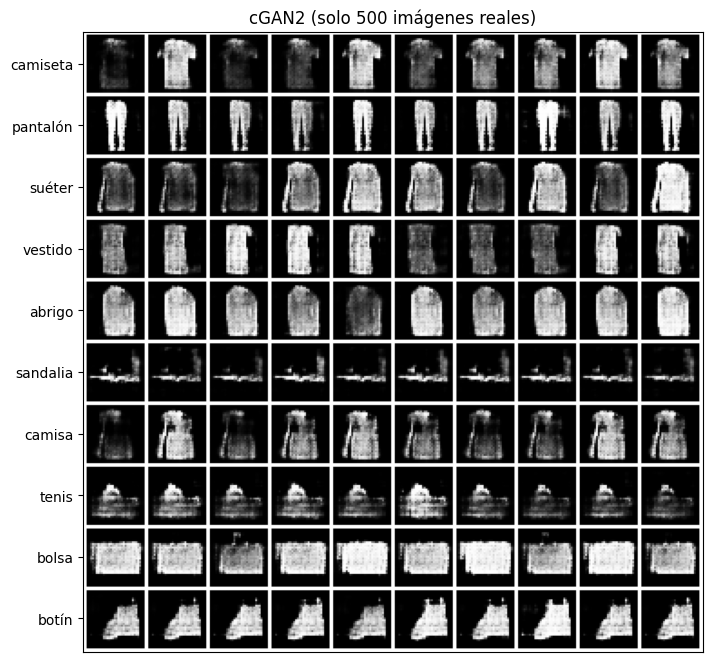

In [13]:
ITER_LIMITADO = 3000
G_honesta, h_honesta = entrenar_cgan(X_lim, Y_lim, ITER_LIMITADO, batch=64, ruido_instancia=0.1, aumento_D=True,
                                     nombre=f"cGAN-{len(X_lim)}")
rejilla_por_clase(G_honesta, f"cGAN2 (solo {len(X_lim)} imágenes reales)")

Entrena otra cGAN2 **sin** `aumento_D` ni ruido (`ruido_instancia=0.0, aumento_D=False`). Compara rejilla, exactitud condicional y FID. ¿Qué le pasa a D con 500 imágenes sin aumento?

[cGAN-500-sinAum] it   500/3000  loss_D 0.877  loss_G 1.782  acc_cond 0.492  FID-d 10.2  (12 s)
[cGAN-500-sinAum] it  1000/3000  loss_D 0.732  loss_G 2.228  acc_cond 0.600  FID-d 7.5  (25 s)
[cGAN-500-sinAum] it  1500/3000  loss_D 0.565  loss_G 2.255  acc_cond 0.555  FID-d 7.9  (37 s)
[cGAN-500-sinAum] it  2000/3000  loss_D 0.632  loss_G 2.376  acc_cond 0.625  FID-d 7.2  (49 s)
[cGAN-500-sinAum] it  2500/3000  loss_D 0.475  loss_G 2.835  acc_cond 0.487  FID-d 14.4  (62 s)
[cGAN-500-sinAum] it  3000/3000  loss_D 0.592  loss_G 3.538  acc_cond 0.700  FID-d 5.3  (74 s)


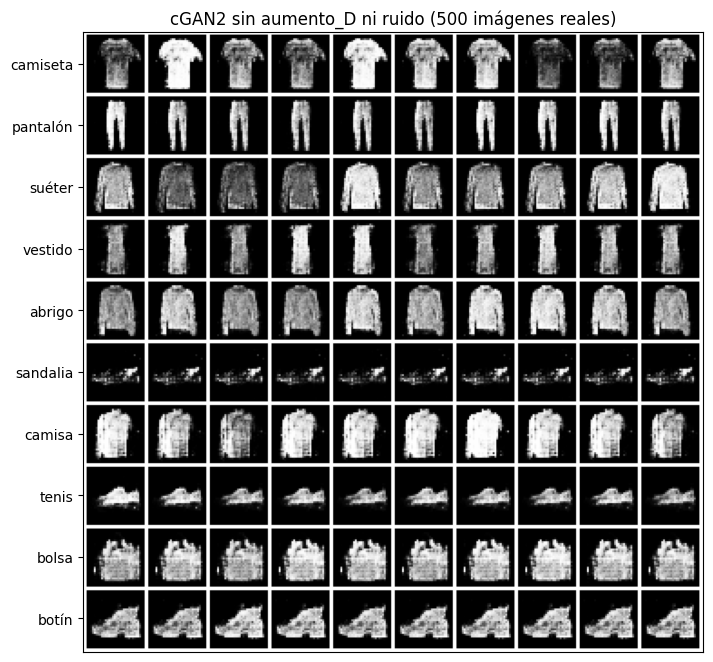

,modelo,loss_D,loss_G,D_x,D_Gz,acc_condicional,fid_dominio
0,Con aumento_D + ruido,1.376,1.651,0.458,0.416,0.576,6.94
1,Sin aumento_D ni ruido,0.592,3.538,0.833,0.154,0.700,5.35


In [14]:
# ✍️ TU TURNO C.1
G_sin_aum, h_sin_aum = entrenar_cgan(
    X_lim, Y_lim, ITER_LIMITADO, batch=64,
    ruido_instancia=0.0, aumento_D=False,
    nombre=f"cGAN-{len(X_lim)}-sinAum"
)
rejilla_por_clase(G_sin_aum, f"cGAN2 sin aumento_D ni ruido ({len(X_lim)} imágenes reales)")

comp_c1 = pd.DataFrame([
    dict(modelo="Con aumento_D + ruido", **h_honesta.iloc[-1][["loss_D", "loss_G", "D_x", "D_Gz", "acc_condicional", "fid_dominio"]].to_dict()),
    dict(modelo="Sin aumento_D ni ruido", **h_sin_aum.iloc[-1][["loss_D", "loss_G", "D_x", "D_Gz", "acc_condicional", "fid_dominio"]].to_dict()),
]).round(3)
display(comp_c1)

Al comparar ambas corridas se nota rápido qué le pasa al discriminador sin aumento ni ruido. Con solo 500 imágenes reales, `loss_D` cae a 0.592, `D(x)` sube a 0.833 y `D(G(z))` cae a 0.154, mientras `loss_G` se dispara hasta 3.538. El discriminador memoriza el conjunto pequeño y rechaza la mayoría de las muestras que produce el generador.

Con `aumento_D=True` y `ruido_instancia=0.1` el juego adversarial se mantiene mucho más equilibrado (`loss_D = 1.376`, `loss_G = 1.651`, `D(x) = 0.458`, `D(G(z)) = 0.416`) y el FID baja de manera progresiva hasta 6.94. Sin estabilización la última iteración cerró en `acc_condicional = 0.700` y `FID-d = 5.35`, pero el entrenamiento fue mucho más inestable (en la iteración 2500 el FID saltó de golpe hasta 14.4 cuando `loss_D` bajó a 0.475).

R              n=   500  exactitud = 0.789
R+aum          n=   500  exactitud = 0.717
S_honesta      n=  5000  exactitud = 0.450
R+S_honesta    n=  5500  exactitud = 0.650
R+S_fuga ⚠️    n=  5500  exactitud = 0.700
R_60k          n= 60000  exactitud = 0.784


,mean,std
condicion,,
R,0.7890,0.0031
R+aum,0.7174,0.0502
S_honesta,0.4501,0.0110
R+S_honesta,0.6504,0.0581
R+S_fuga ⚠️,0.6995,0.0833
R_60k,0.7842,0.0367


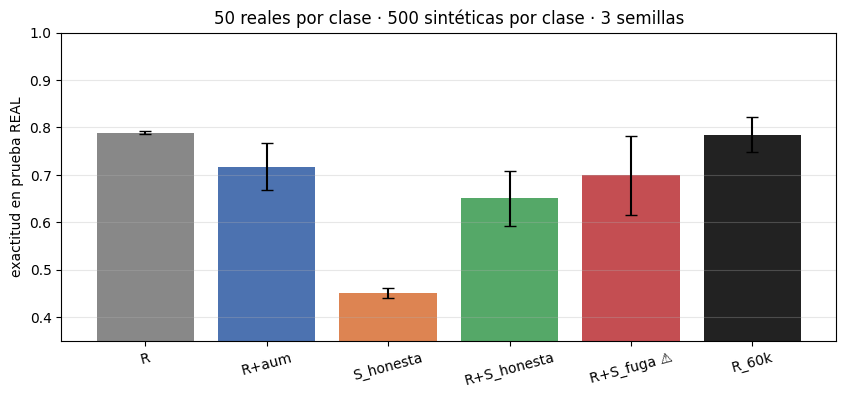

In [15]:
X_sh, Y_sh = muestras_cond(G_honesta, SINT_POR_CLASE, semilla=1)     # sintéticas honestas
X_sf, Y_sf = muestras_cond(G_completo, SINT_POR_CLASE, semilla=1)    # sintéticas con fuga

CONDICIONES = {
    "R":            lambda: (X_lim, Y_lim, False),
    "R+aum":        lambda: (X_lim, Y_lim, True),
    "S_honesta":    lambda: (X_sh, Y_sh, False),
    "R+S_honesta":  lambda: (torch.cat([X_lim, X_sh]), torch.cat([Y_lim, Y_sh]), False),
    "R+S_fuga ⚠️":  lambda: (torch.cat([X_lim, X_sf]), torch.cat([Y_lim, Y_sf]), False),
    "R_60k":        lambda: (X_tr, Y_tr, False),
}
filas, preds = [], {}
for nombre, datos in CONDICIONES.items():
    x, y, aum = datos()
    for s in SEMILLAS:
        acc, pred = entrenar_clasificador(x, y, aumento=aum, semilla=s)
        filas.append(dict(condicion=nombre, semilla=s, exactitud=acc, n_imagenes=len(x))); preds[(nombre, s)] = pred
    print(f"{nombre:<14s} n={len(x):>6}  exactitud = {np.mean([f['exactitud'] for f in filas if f['condicion'] == nombre]):.3f}")

res_aumento = pd.DataFrame(filas)
resumen_aum = res_aumento.groupby("condicion", sort=False).exactitud.agg(["mean", "std"]).round(4)
display(resumen_aum)
res_aumento.to_csv(f"aumento_sintetico_N{N_POR_CLASE}.csv", index=False)

plt.figure(figsize=(10, 4))
colores = ["#888", "#4c72b0", "#dd8452", "#55a868", "#c44e52", "#222"]
plt.bar(resumen_aum.index, resumen_aum["mean"], yerr=resumen_aum["std"], capsize=4, color=colores)
plt.ylim(max(0, resumen_aum["mean"].min() - 0.1), 1); plt.ylabel("exactitud en prueba REAL")
plt.title(f"{N_POR_CLASE} reales por clase · {SINT_POR_CLASE} sintéticas por clase · {len(SEMILLAS)} semillas")
plt.xticks(rotation=15); plt.grid(axis="y", alpha=.3); plt.savefig(f"aumento_sintetico_N{N_POR_CLASE}.png", dpi=110); plt.show()

In [16]:
# ¿En qué clases ayudaron (o dañaron) las sintéticas honestas? Diferencia de exactitud por clase vs. "R"
def acc_por_clase(nombre):
    return np.mean([[(preds[(nombre, s)][Y_te == c] == c).float().mean().item() for c in range(N_CLASES)] for s in SEMILLAS], axis=0)
dif = pd.DataFrame({"clase": CLASES,
                    "R": acc_por_clase("R"),
                    "Δ R+aum": acc_por_clase("R+aum") - acc_por_clase("R"),
                    "Δ R+S_honesta": acc_por_clase("R+S_honesta") - acc_por_clase("R")})
display(dif.round(3))

,clase,R,Δ R+aum,Δ R+S_honesta
0,camiseta,0.755,-0.209,-0.113
1,pantalón,0.933,-0.005,-0.013
2,suéter,0.709,-0.192,0.054
3,vestido,0.776,-0.123,-0.334
4,abrigo,0.570,0.036,-0.150
5,sandalia,0.882,-0.050,-0.156
6,camisa,0.549,0.007,-0.350
7,tenis,0.927,-0.048,-0.076
8,bolsa,0.905,-0.156,-0.227
9,botín,0.884,0.024,-0.021


Ordena las condiciones por exactitud. ¿Ayudó la cGAN honesta frente a `R`? ¿Y frente a `R+aum`? Responde con **media ± desviación** y discute si la diferencia es mayor que la variación entre semillas.

 Explica con tus palabras por qué `R+S_fuga` **no** es un resultado válido aunque dé la mejor exactitud. ¿En qué situación real se cometería este error sin darse cuenta?

¿Qué te dice `S_honesta` (TSTR) sobre la calidad de las sintéticas? ¿En qué clases la cGAN honesta ayudó o dañó más (tabla por clase)?

---

De mayor a menor exactitud en prueba real (3 semillas), el orden fue: `R` (0.7890 ± 0.0031), `R_60k` (0.7842 ± 0.0367), `R+aum` (0.7174 ± 0.0502), `R+S_fuga` (0.6995 ± 0.0833), `R+S_honesta` (0.6504 ± 0.0581) y `S_honesta` (0.4501 ± 0.0110). La cGAN honesta no ayudó frente a `R`: bajó el desempeño casi 14 puntos porcentuales, una caída mucho mayor que la desviación entre semillas. También quedó por debajo de `R+aum` por cerca de 6.7 puntos, porque las 5000 sintéticas dominan los 800 pasos fijos de entrenamiento y diluyen la señal de las 500 imágenes reales.

`R+S_fuga` no sirve como resultado válido porque su generador (`G_completo`) vio las 60 000 imágenes reales antes de crear las sintéticas. Aunque al clasificador solo le entreguemos 500 reales, las muestras generadas filtran información de las otras 59 500 imágenes y rompen el protocolo del experimento. En un proyecto real este error pasa fácilmente cuando alguien entrena una GAN o un autoencoder con el dataset completo antes de separar entrenamiento y prueba, o cuando descarga un generador preentrenado cuyo conjunto original se solapa con el de evaluación.

El resultado de `S_honesta` (0.4501 ± 0.0110) deja claro que las imágenes creadas con solo 50 ejemplos por clase pierden demasiados detalles discriminativos como para entrenar un clasificador por sí solas. En la tabla por clase, las sintéticas honestas solo mejoraron ligeramente a suéter (+0.054), mientras que dañaron bastante a camisa (-0.350), vestido (-0.334), bolsa (-0.227), sandalia (-0.156) y abrigo (-0.150).

## Parte D

Prof asigna un equipo variación, la ejecuta (vuelve a correr la Parte C con el cambio) y la presenta en 2 minutos en clase + pregunta:

| Equipo | Variación | Pregunta |
|---|---|---|
| 1 | `N_POR_CLASE = 20` | ¿Con aún menos datos las sintéticas ayudan más o menos? |
| 2 | `N_POR_CLASE = 200` | ¿A partir de cuántos datos reales deja de valer la pena? |
| 3 | `SINT_POR_CLASE = 50` y `= 2000` | ¿Más sintéticas = mejor? ¿Hay saturación? |
| 4 | cGAN honesta sin aumento diferenciable | ¿Cuánto importa estabilizar la cGAN para que las sintéticas sirvan? |
| 5 | Combinar `R+aum` **y** sintéticas honestas | ¿Son complementarias las dos formas de aumento? |
| 6 | Filtrar sintéticas: conservar solo las que el juez clasifica con confianza > 0.9 en su clase | ¿Filtrar por calidad ayuda? (cuidado: ¿el juez vio datos que no debería?) |

,mean,std
condicion,,
R,0.7878,0.0034
R+aum,0.7350,0.0603
R+S_honesta,0.6544,0.0748
R+aum+S_honesta,0.6310,0.0185


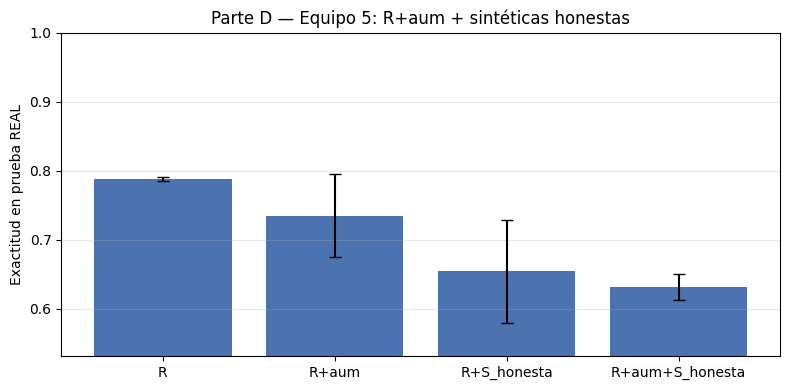

In [17]:
# Parte D — Equipo 5: combinar R+aum y sintéticas honestas
conds_d = {
    "R":               (X_lim, Y_lim, False),
    "R+aum":           (X_lim, Y_lim, True),
    "R+S_honesta":     (torch.cat([X_lim, X_sh]), torch.cat([Y_lim, Y_sh]), False),
    "R+aum+S_honesta": (torch.cat([X_lim, X_sh]), torch.cat([Y_lim, Y_sh]), True),
}

filas_d = []
for nombre, (x, y, aum) in conds_d.items():
    for s in SEMILLAS:
        acc, _ = entrenar_clasificador(x, y, aumento=aum, semilla=s)
        filas_d.append(dict(condicion=nombre, semilla=s, exactitud=acc))

resumen_d = pd.DataFrame(filas_d).groupby("condicion", sort=False).exactitud.agg(["mean", "std"]).round(4)
display(resumen_d)

plt.figure(figsize=(8, 4))
plt.bar(resumen_d.index, resumen_d["mean"], yerr=resumen_d["std"], capsize=4, color="#4c72b0")
plt.ylim(max(0, resumen_d["mean"].min() - 0.1), 1)
plt.ylabel("Exactitud en prueba REAL"); plt.title("Parte D — Equipo 5: R+aum + sintéticas honestas")
plt.grid(axis="y", alpha=0.3); plt.tight_layout(); plt.show()

En la variación del Equipo 5 los resultados fueron `R` = 0.7878 ± 0.0034, `R+aum` = 0.7350 ± 0.0603, `R+S_honesta` = 0.6544 ± 0.0748 y `R+aum+S_honesta` = 0.6310 ± 0.0185.

En este escenario las dos formas de aumento no resultaron complementarias. Combinar `R+aum` con las sintéticas honestas redujo la variación entre semillas (std de 0.0185 frente a 0.0748 en `R+S_honesta`), pero la media cayó ligeramente a 0.6310 y quedó lejos tanto de `R` como de `R+aum`. Como alrededor del 90% de los datos vistos siguen siendo sintéticos con artefactos, aplicar aumento clásico encima no logra compensar el ruido de las muestras generadas.

# Parte E
Ejecuta con tus datos reales, compara 1 variación y grafica 16 imagenes generas por cGAN y por Aumentación

Como el proyecto integrador trata sobre síntesis de caligrafía manuscrita mediante cGAN, aquí usamos **MNIST** (dígitos manuscritos reales normalizados a 32×32) con el mismo escenario de pocos datos (50 imágenes reales por clase, 500 en total). Para la aumentación clásica evitamos el espejo horizontal, ya que invierte dígitos como `2`, `3` o `5`, y aplicamos únicamente traslaciones de ±2 px y rotaciones de ±12°.

Juez: exactitud en prueba real = 0.918
MNIST limitado: 500 imágenes reales (50 por clase)
[cGAN-MNIST-500] it  500/2500  acc_cond 0.361  FID-d 9.5  (12 s)
[cGAN-MNIST-500] it 1000/2500  acc_cond 0.455  FID-d 13.0  (25 s)
[cGAN-MNIST-500] it 1500/2500  acc_cond 0.441  FID-d 10.3  (37 s)
[cGAN-MNIST-500] it 2000/2500  acc_cond 0.637  FID-d 7.4  (49 s)
[cGAN-MNIST-500] it 2500/2500  acc_cond 0.693  FID-d 6.4  (61 s)


,mean,std
condicion,,
R (500 reales),0.9101,0.0051
R+aum (clásica),0.8942,0.0441
R+S_honesta (cGAN),0.6646,0.1547
R+aum+S_honesta (variación),0.7795,0.0588


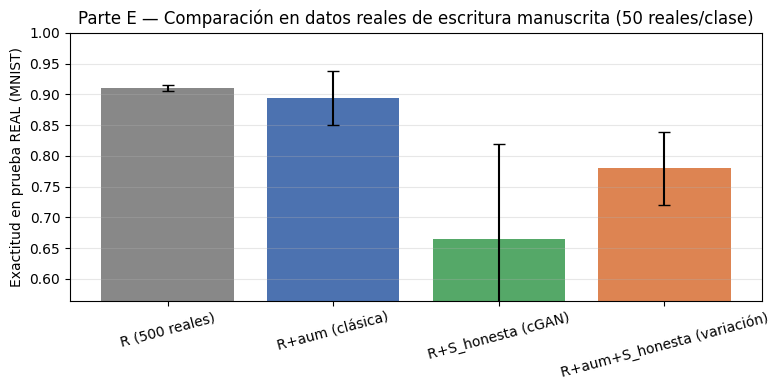

In [18]:
# Parte E — Experimento en datos reales del dominio de escritura manuscrita (MNIST, 50 imágenes por clase)
import torchvision.transforms.functional as TF

X_tr_e, Y_tr_e = cargar_tensor("MNIST", "train")
X_te_e, Y_te_e = cargar_tensor("MNIST", "test")

# Juez evaluador externo para MNIST (para medir acc_condicional y FID de dominio)
juez_e, _ = entrenar_juez(X_tr_e, Y_tr_e, X_te_e, Y_te_e, epocas=3, verbose=True)

# Subconjunto limitado honesto: 50 imágenes reales por clase (500 en total)
N_LIM_E = 50
g_cpu = torch.Generator(device="cpu").manual_seed(0)
idx_e = torch.cat([torch.nonzero(Y_tr_e.cpu() == c).view(-1)[torch.randperm(int((Y_tr_e == c).sum()), generator=g_cpu)[:N_LIM_E]]
                   for c in range(10)])
X_lim_e, Y_lim_e = X_tr_e[idx_e.to(DEVICE)], Y_tr_e[idx_e.to(DEVICE)]
print(f"MNIST limitado: {len(X_lim_e)} imágenes reales ({N_LIM_E} por clase)")

def aumento_manuscrito(xb):
    """Aumentación clásica válida para caligrafía: desplazamiento ±2 px y rotación ±12° (sin espejo horizontal)."""
    dx, dy = int(np.random.randint(-2, 3)), int(np.random.randint(-2, 3))
    xb = torch.roll(xb, shifts=(dx, dy), dims=(2, 3))
    ang = float(np.random.uniform(-12, 12))
    return TF.rotate(xb, ang, fill=-1.0)

def entrenar_cgan_e(x, y, iteraciones=2500, batch=64, nz=100, suavizado=0.9, ruido_instancia=0.1, aumento_D=True, semilla=0, nombre="cGAN-MNIST"):
    fijar_semilla(semilla)
    G = GeneradorCond(nz, 10, 50, 64, 1).to(DEVICE)
    D = DiscriminadorCond(10, 64, 1).to(DEVICE)
    G.apply(init_dcgan); D.apply(init_dcgan)
    oG = torch.optim.Adam(G.parameters(), 2e-4, betas=(0.5, 0.999))
    oD = torch.optim.Adam(D.parameters(), 2e-4, betas=(0.5, 0.999))
    bce = nn.BCEWithLogitsLoss()
    flujo = iter(()); t0 = time.time()
    for it in range(1, iteraciones + 1):
        try: xr, yr = next(flujo)
        except StopIteration:
            flujo = lotes(x, y, batch); xr, yr = next(flujo)
        b = len(xr); sigma = ruido_instancia * (1 - it / iteraciones)
        def rd(t):
            if sigma > 0: t = t + sigma * torch.randn_like(t)
            if aumento_D:
                dx, dy = int(np.random.randint(-2, 3)), int(np.random.randint(-2, 3))
                t = torch.roll(t, shifts=(dx, dy), dims=(2, 3))
            return t
        yf = torch.randint(0, 10, (b,), device=DEVICE)
        with torch.no_grad(): xf = G(torch.randn(b, nz, device=DEVICE), yf)
        lD = bce(D(rd(xr), yr), torch.full((b,), suavizado, device=DEVICE)) + bce(D(rd(xf), yf), torch.zeros(b, device=DEVICE))
        oD.zero_grad(); lD.backward(); oD.step()
        yg = torch.randint(0, 10, (b,), device=DEVICE)
        lG = bce(D(rd(G(torch.randn(b, nz, device=DEVICE), yg)), yg), torch.ones(b, device=DEVICE))
        oG.zero_grad(); lG.backward(); oG.step()
        if it % 500 == 0 or it == iteraciones:
            xs, ys = muestras_cond(G, 100, nz, semilla=123)
            acc_c = (juez_e.probabilidades(xs).argmax(1) == ys).float().mean().item()
            fid_c = fid_dominio(juez_e, X_te_e[:len(xs)], xs)
            print(f"[{nombre}] it {it:>4}/{iteraciones}  acc_cond {acc_c:.3f}  FID-d {fid_c:.1f}  ({time.time()-t0:.0f} s)")
    return G

# Entrenar cGAN honesta sobre los 500 dígitos manuscritos reales
G_e = entrenar_cgan_e(X_lim_e, Y_lim_e, iteraciones=2500, ruido_instancia=0.1, aumento_D=True, nombre="cGAN-MNIST-500")

# Comparación de 1 variación: R vs R+aum (clásica) vs R+S_honesta (cGAN) vs R+aum+S_honesta (combinada)
X_sh_e, Y_sh_e = muestras_cond(G_e, 500, semilla=1)

def entrenar_clf_e(x, y, pasos=600, batch=64, usar_aum=False, semilla=0):
    fijar_semilla(semilla)
    m = Juez(1, 10).to(DEVICE); opt = torch.optim.Adam(m.parameters(), 1e-3)
    flujo = iter(()); batch = min(batch, len(x))
    for _ in range(pasos):
        try: xb, yb = next(flujo)
        except StopIteration:
            flujo = lotes(x, y, batch); xb, yb = next(flujo)
        if usar_aum: xb = aumento_manuscrito(xb)
        m.train(); loss = F.cross_entropy(m(xb), yb)
        opt.zero_grad(); loss.backward(); opt.step()
    return (m.probabilidades(X_te_e).argmax(1) == Y_te_e).float().mean().item()

conds_e = {
    "R (500 reales)": (X_lim_e, Y_lim_e, False),
    "R+aum (clásica)": (X_lim_e, Y_lim_e, True),
    "R+S_honesta (cGAN)": (torch.cat([X_lim_e, X_sh_e]), torch.cat([Y_lim_e, Y_sh_e]), False),
    "R+aum+S_honesta (variación)": (torch.cat([X_lim_e, X_sh_e]), torch.cat([Y_lim_e, Y_sh_e]), True),
}
filas_e = []
for nombre, (x, y, aum) in conds_e.items():
    for s in [0, 1, 2]:
        filas_e.append(dict(condicion=nombre, semilla=s, exactitud=entrenar_clf_e(x, y, usar_aum=aum, semilla=s)))
res_e = pd.DataFrame(filas_e).groupby("condicion", sort=False).exactitud.agg(["mean", "std"]).round(4)
display(res_e)

plt.figure(figsize=(8, 4))
plt.bar(res_e.index, res_e["mean"], yerr=res_e["std"], capsize=4, color=["#888", "#4c72b0", "#55a868", "#dd8452"])
plt.ylim(max(0, res_e["mean"].min() - 0.1), 1); plt.ylabel("Exactitud en prueba REAL (MNIST)")
plt.title("Parte E — Comparación en datos reales de escritura manuscrita (50 reales/clase)")
plt.xticks(rotation=15); plt.grid(axis="y", alpha=0.3); plt.tight_layout(); plt.show()

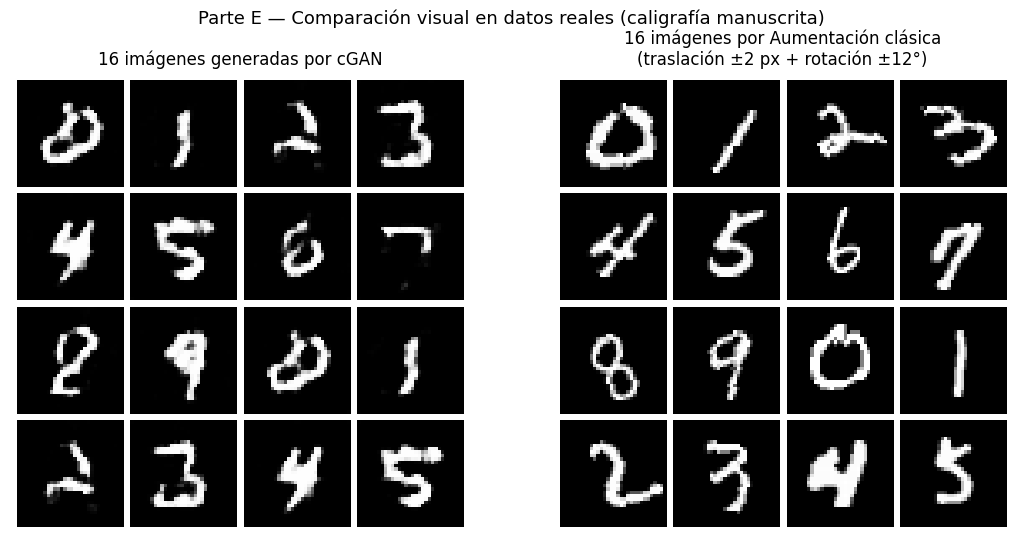

In [19]:
# Parte E — Gráfica comparativa: 16 imágenes generadas por cGAN vs. 16 imágenes generadas por Aumentación clásica
fijar_semilla(42)
G_e.eval()
with torch.no_grad():
    y_16 = torch.arange(16, device=DEVICE) % 10
    imgs_cgan_16 = G_e(torch.randn(16, 100, device=DEVICE), y_16).cpu()

# 16 imágenes reales de las mismas clases pasadas por aumentación clásica (traslación + rotación)
imgs_aum_16 = []
for c in y_16.cpu().tolist():
    candidatos = X_lim_e[Y_lim_e == c]
    muestra = candidatos[np.random.randint(0, len(candidatos))].unsqueeze(0)
    imgs_aum_16.append(aumento_manuscrito(muestra))
imgs_aum_16 = torch.cat(imgs_aum_16, dim=0).cpu()

fig, axes = plt.subplots(1, 2, figsize=(11, 5.5))
g_cgan = make_grid(imgs_cgan_16, nrow=4, normalize=True, value_range=(-1, 1), pad_value=1)
g_aum = make_grid(imgs_aum_16, nrow=4, normalize=True, value_range=(-1, 1), pad_value=1)

axes[0].imshow(g_cgan.permute(1, 2, 0).numpy(), cmap="gray")
axes[0].set_title("16 imágenes generadas por cGAN", fontsize=12); axes[0].axis("off")

axes[1].imshow(g_aum.permute(1, 2, 0).numpy(), cmap="gray")
axes[1].set_title("16 imágenes por Aumentación clásica\n(traslación ±2 px + rotación ±12°)", fontsize=12); axes[1].axis("off")

plt.suptitle("Parte E — Comparación visual en datos reales (caligrafía manuscrita)", fontsize=13)
plt.tight_layout(); plt.savefig("parte_e_cgan_vs_aumentacion.png", dpi=120); plt.show()

Con 50 dígitos manuscritos reales por clase en MNIST, `R` alcanzó 0.9101 ± 0.0051 y `R+aum` quedó en 0.8942 ± 0.0441. Al sumar muestras sintéticas de la cGAN (`R+S_honesta`) la exactitud cayó a 0.6646 ± 0.1547, mientras que la variación combinada (`R+aum+S_honesta`) recuperó más de 11 puntos hasta 0.7795 ± 0.0588 y redujo mucho la variabilidad entre semillas, aunque siguió por debajo de entrenar solo con reales.

Al comparar las dos rejillas de 16 imágenes se entiende la diferencia. Las 16 muestras por aumentación clásica mantienen bordes limpios y la forma exacta de cada dígito con pequeñas inclinaciones y desplazamientos; en cambio, las 16 imágenes de la cGAN generan trazos nuevos pero con ruido de fondo y varios dígitos deformados al haber entrenado solo con 50 ejemplos por clase.